# Определение оттока

Порог неактивности N, когорты, портрет активных клиентов на точке проверки 2026-01-01 и базовая частота оттока по точкам прогноза. Данные — витрины `mart`.

In [1]:
from datetime import timedelta

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from churn.db import connect
from churn.features import query
from churn.params import CHURN_N, TEST_POINT

pd.set_option("display.precision", 3)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": "#e6e5e0", "grid.linewidth": 0.8, "lines.linewidth": 2})
COLORS = {"cat_food": "#eb6834", "dog_food": "#2a78d6", "accessories": "#1baf7a", "all": "#3d3d3a"}
GRAY = "#8a8984"

with connect() as conn:
    fc = query(conn, "select * from mart.false_churn")
    coh = query(conn, "select * from mart.cohort_retention")
    md = query(conn, "select * from mart.model_dataset")
    last = query(conn, """
        select customer_id, count(*) as n_180, sum(margin)::float8 as margin_180 from mart.purchases
        where order_date >= %s and order_date < %s group by 1""", (TEST_POINT - timedelta(days=180), TEST_POINT))
fc[["share"]] = fc[["share"]].astype(float)
coh[["retention", "cum_margin"]] = coh[["retention", "cum_margin"]].astype(float)

## Ложный отток по порогу N

Среди пауз после покупки длиннее N дней — доля тех, кто купил снова в следующие 365 дней. Только паузы, у которых эти 365 дней целиком есть в данных. Сегмент — основная категория клиента на момент покупки.

In [2]:
share = fc[fc["pause"] == "all"].pivot(index="n", columns="segment", values="share")[list(COLORS)]
share

segment,cat_food,dog_food,accessories,all
n,,,,
60,0.182,0.376,0.466,0.334
90,0.030,0.076,0.279,0.116
120,0.008,0.014,0.148,0.047
180,0.002,0.002,0.034,0.010


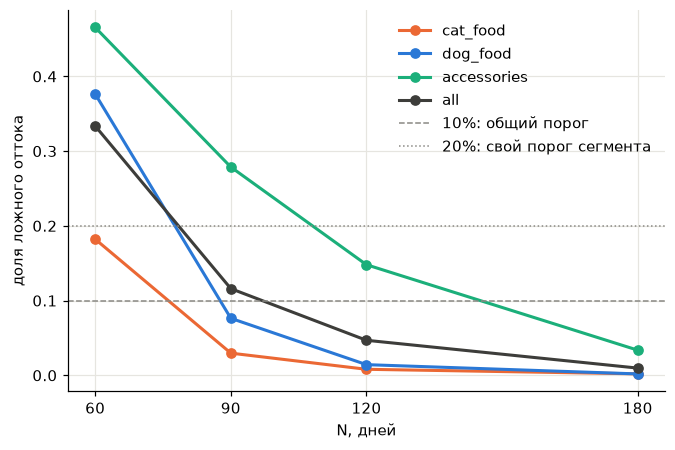

In [3]:
fig, ax = plt.subplots(figsize=(7, 4.5))
for seg, c in COLORS.items():
    ax.plot(share.index, share[seg], color=c, marker="o", markersize=6, label=seg)
ax.axhline(0.10, color=GRAY, linewidth=1, linestyle="--", label="10%: общий порог")
ax.axhline(0.20, color=GRAY, linewidth=1, linestyle=":", label="20%: свой порог сегмента")
ax.set(xlabel="N, дней", ylabel="доля ложного оттока", xticks=share.index)
ax.legend(frameon=False)
plt.show()

Наименьший N, при котором общая доля не больше 10%, — 120 дней. При N = 120 ни один сегмент не выше 20%, поэтому порог один для всех.

### Первая пауза и повторные при N = 120

In [4]:
n120 = fc[fc["n"] == CHURN_N].pivot(index="segment", columns="pause", values=["pauses_over_n", "share"])
n120.columns = [f"{a} {b}" for a, b in n120.columns]
n120 = n120.loc[list(COLORS)]
n120["доля первых пауз"] = n120["pauses_over_n first"] / n120["pauses_over_n all"]
n120

,pauses_over_n all,pauses_over_n first,pauses_over_n repeat,share all,share first,share repeat,доля первых пауз
segment,,,,,,,
cat_food,5791.0,3602.0,2189.0,0.008,0.007,0.011,0.622
dog_food,4490.0,3011.0,1479.0,0.014,0.006,0.032,0.671
accessories,3669.0,2535.0,1134.0,0.148,0.066,0.331,0.691
all,13950.0,9148.0,4802.0,0.047,0.023,0.093,0.656


Общая доля — среднее долей первой и повторных пауз с весами по числу пауз. Магазин в данных начинается с нуля, и в наблюдаемое окно попадают в основном паузы после первой покупки: их около двух третей. После первой покупки многие уходят навсегда, из таких пауз возвращаются единицы процентов, поэтому общая доля ниже, чем у повторных покупателей.

In [5]:
acc = fc[(fc["n"] == CHURN_N) & (fc["segment"] == "accessories") & (fc["pause"] == "repeat")].iloc[0]
print(f"повторные покупатели аксессуаров, N = {CHURN_N}: пауз {acc['pauses_over_n']}, "
      f"вернулись {acc['returned']}, доля ложного оттока {acc['share']:.3f}")

повторные покупатели аксессуаров, N = 120: пауз 1134, вернулись 375, доля ложного оттока 0.331


У повторных покупателей аксессуаров примерно каждый третий «ушедший» возвращается: для них отток по N = 120 завышен. Правило не меняем, выводы по сегменту проверяем с порогом 180 дней (см. docs/churn_definition.md).

## Когорты

Когорта — месяц первой покупки. Retention — доля когорты, купившая в месяце k после первого. Последний полный месяц — 2026-06, у поздних когорт ряды короче.

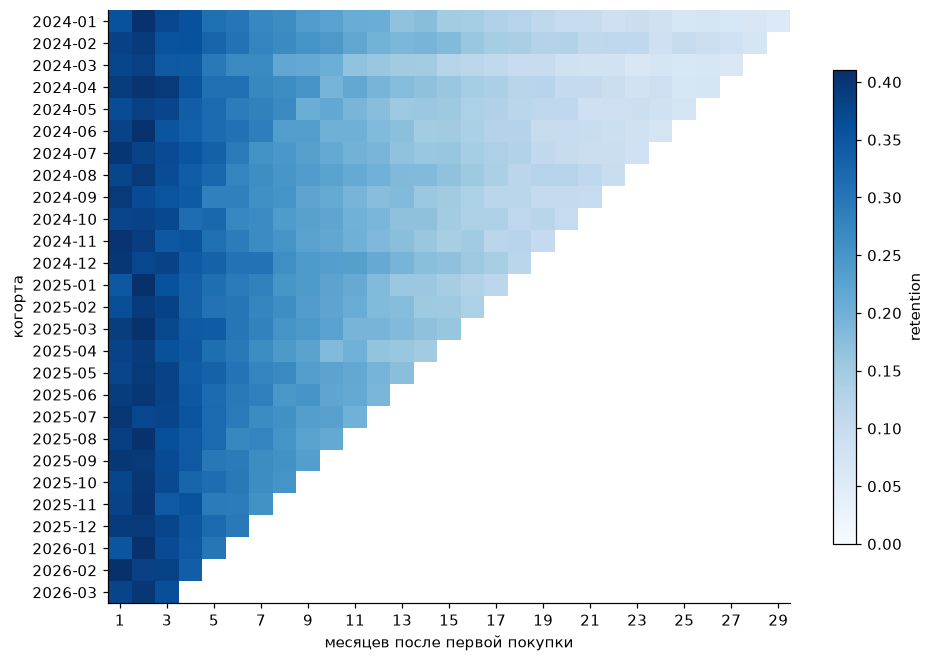

In [6]:
ret = coh.pivot(index="cohort", columns="k", values="retention").drop(columns=0)
fig, ax = plt.subplots(figsize=(10, 7))
im = ax.imshow(ret, cmap="Blues", aspect="auto", vmin=0)
ax.set(xticks=range(0, ret.shape[1], 2), xticklabels=ret.columns[::2], yticks=range(len(ret)),
       yticklabels=[d.strftime("%Y-%m") for d in ret.index], xlabel="месяцев после первой покупки", ylabel="когорта")
ax.grid(False)
fig.colorbar(im, ax=ax, label="retention", shrink=0.8)
plt.show()

In [7]:
ret[[1, 2, 3, 6, 12]].iloc[::3]

k,1,2,3,6,12
cohort,,,,,
2024-01-01,0.358,0.406,0.373,0.300,0.206
2024-04-01,0.391,0.402,0.393,0.311,0.193
2024-07-01,0.400,0.380,0.367,0.292,0.191
2024-10-01,0.377,0.379,0.372,0.274,0.190
2025-01-01,0.347,0.408,0.359,0.292,0.182
2025-04-01,0.379,0.393,0.356,0.294,0.165
2025-07-01,0.399,0.373,0.377,0.293,NaN
2025-10-01,0.374,0.399,0.369,0.295,NaN
2026-01-01,0.353,0.407,0.366,NaN,NaN


Когорты почти не отличаются друг от друга: в первые три месяца после первой покупки покупает 35–41% когорты, через год — 17–21%.

Накопленная маржа на клиента когорты: маржа всех покупок с первого месяца, делённая на размер когорты.

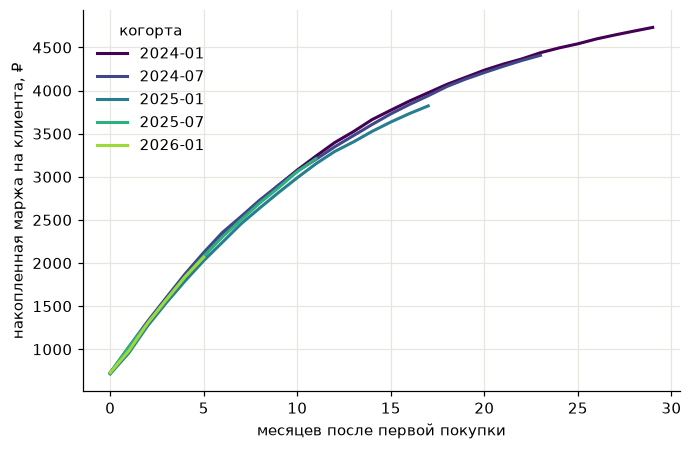

In [8]:
picks = ["2024-01-01", "2024-07-01", "2025-01-01", "2025-07-01", "2026-01-01"]
cum = coh.pivot(index="k", columns="cohort", values="cum_margin")
fig, ax = plt.subplots(figsize=(7, 4.5))
for c, color in zip(picks, plt.cm.viridis(np.linspace(0, 0.85, len(picks)))):
    s = cum[pd.Timestamp(c).date()].dropna()
    ax.plot(s.index, s, color=color, label=c[:7])
ax.set(xlabel="месяцев после первой покупки", ylabel="накопленная маржа на клиента, ₽")
ax.legend(frameon=False, title="когорта")
plt.show()

Кривые когорт почти совпадают: около 730 ₽ на клиента в первый месяц, 2 300 ₽ к шестому, 3 300–3 400 ₽ к двенадцатому. Дальше рост замедляется: остаются только повторные покупатели.

## Портрет активных клиентов на 2026-01-01

Активные — с покупкой за 120 дней до точки. Churn — нет покупки в [T, T + 120). Медианный интервал — медиана по клиентам их медианного интервала между покупками. Средний чек — net всех покупок до T, делённый на их число. Покупки и маржа — за 180 дней до T, на клиента.

In [9]:
t = md[md["is_test"]].merge(last, on="customer_id", how="left").fillna({"n_180": 0, "margin_180": 0.0})
t["покупки"] = np.where(t["purchases"] == 1, "одна покупка", "повторные")


def portrait(g):
    return {
        "активных": len(g),
        "доля churn": g["churn"].mean(),
        "медианный интервал, дней": g["median_gap"].median(),
        "покупок за 180 дней": g["n_180"].mean(),
        "средний чек net, ₽": g["net_total"].sum() / g["purchases"].sum(),
        "маржа за 180 дней, ₽": g["margin_180"].mean(),
    }


groups = {k: g for k, g in t.groupby(["main_category", "покупки"])}
groups |= {(c, "все"): g for c, g in t.groupby("main_category")}
groups |= {("все", p): g for p, g in t.groupby("покупки")} | {("все", "все"): t}
port = pd.DataFrame({k: portrait(g) for k, g in groups.items()}).T.sort_index()
port["активных"] = port["активных"].astype(int)
port.round({"средний чек net, ₽": 0, "маржа за 180 дней, ₽": 0})

активных  доля churn  медианный интервал, дней  \
accessories все               4081       0.419                      46.0   
            одна покупка      1478       0.681                       NaN   
            повторные         2603       0.270                      46.0   
cat_food    все               8964       0.359                      28.5   
            одна покупка      2126       0.696                       NaN   
            повторные         6838       0.255                      28.5   
dog_food    все               7734       0.311                      37.5   
            одна покупка      1876       0.646                       NaN   
            повторные         5858       0.204                      37.5   
все         все              20779       0.353                      33.5   
            одна покупка      5480       0.675                       NaN   
            повторные        15299       0.238                      33.5   

                          покупок за 180 дней  средний чек net, ₽  \
accessories все                         2.188              1780.0   
            одна покупка                1.000              1553.0   
            повторные                   2.863              1804.0   
cat_food    все                         3.810              1990.0   
            одна покупка                1.000              1885.0   
            повторные                   4.683              1994.0   
dog_food    все                         3.124              3006.0   
            одна покупка                1.000              3314.0   
            повторные                   3.804              2992.0   
все         все                         3.236              2347.0   
            одна покупка                1.000              2285.0   
            повторные                   4.037              2350.0   

                          маржа за 180 дней, ₽  
accessories все                         1515.0  
            одна покупка                 686.0  
            повторные                   1986.0  
cat_food    все                         2210.0  
            одна покупка                 545.0  
            повторные                   2728.0  
dog_food    все                         2361.0  
            одна покупка                 792.0  
            повторные                   2863.0  
все         все                         2130.0  
            одна покупка                 667.0  
            повторные                   2653.0

Клиенты с одной покупкой — около четверти активных, но у них churn около 0.68 против 0.24 у повторных, и маржа за 180 дней в четыре раза меньше. Среди повторных самый длинный интервал и самый высокий churn у покупателей аксессуаров (46 дней, 0.27): часть этого оттока ложная, см. выше. Собачий корм — самый дорогой чек и самая большая маржа на клиента.

## Базовая частота оттока по точкам прогноза

Все активные клиенты на каждой точке: точки обучения с 2024-07-01 по 2025-09-01 и точка проверки 2026-01-01.

In [10]:
md["покупки"] = np.where(md["purchases"] == 1, "одна покупка", "повторные")
base = md.groupby("point").agg(клиентов=("churn", "size"), churn=("churn", "mean"))
base["доля с одной покупкой"] = (md["покупки"] == "одна покупка").groupby(md["point"]).mean()
base = base.join(md.pivot_table(index="point", columns="покупки", values="churn").add_prefix("churn: "))
base

,клиентов,churn,доля с одной покупкой,churn: одна покупка,churn: повторные
point,,,,,
2024-07-01,7158,0.428,0.485,0.669,0.201
2024-08-01,8002,0.410,0.438,0.674,0.204
2024-09-01,8925,0.404,0.407,0.685,0.211
2024-10-01,9668,0.397,0.384,0.685,0.218
2024-11-01,10465,0.389,0.365,0.684,0.220
2024-12-01,11254,0.384,0.352,0.678,0.225
2025-01-01,11983,0.379,0.333,0.685,0.226
2025-02-01,12724,0.380,0.320,0.694,0.232
2025-03-01,13378,0.378,0.315,0.685,0.237


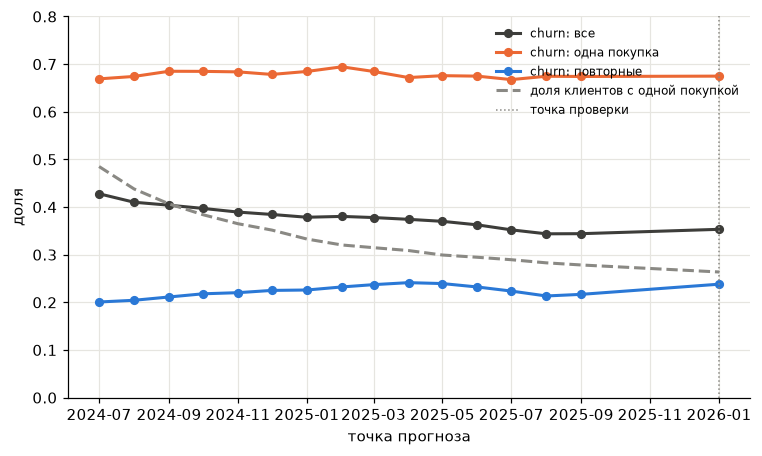

In [11]:
x = pd.to_datetime(base.index)
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(x, base["churn"], color=COLORS["all"], marker="o", markersize=5, label="churn: все")
ax.plot(x, base["churn: одна покупка"], color=COLORS["cat_food"], marker="o", markersize=5, label="churn: одна покупка")
ax.plot(x, base["churn: повторные"], color=COLORS["dog_food"], marker="o", markersize=5, label="churn: повторные")
ax.plot(x, base["доля с одной покупкой"], color=GRAY, linestyle="--", label="доля клиентов с одной покупкой")
ax.axvline(pd.Timestamp(TEST_POINT), color=GRAY, linewidth=1, linestyle=":", label="точка проверки")
ax.set(xlabel="точка прогноза", ylabel="доля", ylim=(0, 0.8))
ax.legend(frameon=False, loc="upper right", fontsize=8)
plt.show()

Частота оттока снижается из-за состава клиентов, а не поведения. Магазин в данных начинается с нуля: на ранних точках почти половина активных — клиенты с одной покупкой, у которых churn около 0.68. К 2025-09 их доля падает до 0.28. Внутри групп частота почти не меняется: у одной покупки 0.67–0.69 на всех точках, у повторных 0.20–0.24. Одно только изменение состава при неизменных частотах 2024-07 снизило бы churn на 0.10, фактически он снизился на 0.08: частота у повторных немного выросла. На точке проверки 2026-01-01 churn повторных выше, чем на 2025-09 (0.238 против 0.217), и общая частота снова 0.35.